<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/m11-2-galton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Galton and the word "regression"

In [4]:
# @title
# Setup: libraries, colors, and the helper functions
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

PURPLE, GOLD, GRAY, LIGHT, SAND = "#510C76", "#B07A00", "#6E6E6E", "#C9B8D6", "#EFE3C2"
plt.rcParams.update({"font.size": 14, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#444444", "axes.labelcolor": "#222222",
                     "xtick.color": "#444444", "ytick.color": "#444444",
                     "axes.titlesize": 14, "legend.fontsize": 12})

def fit(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    return y.mean() - b1 * x.mean(), b1

plt.rcParams["figure.dpi"] = 110

## Galton's question

In the 1880s, Francis Galton collected the heights of parents and their adult children and asked whether a child's adult height could be predicted from the parents' heights. Mid-parent height is the average of the two parents' heights, with women's heights multiplied by 1.08 so that men and women are comparable. Heights were recorded to the nearest inch, so the plot adds a little jitter to make the dots visible.

*Data: Galton (1886), 928 adult children.*

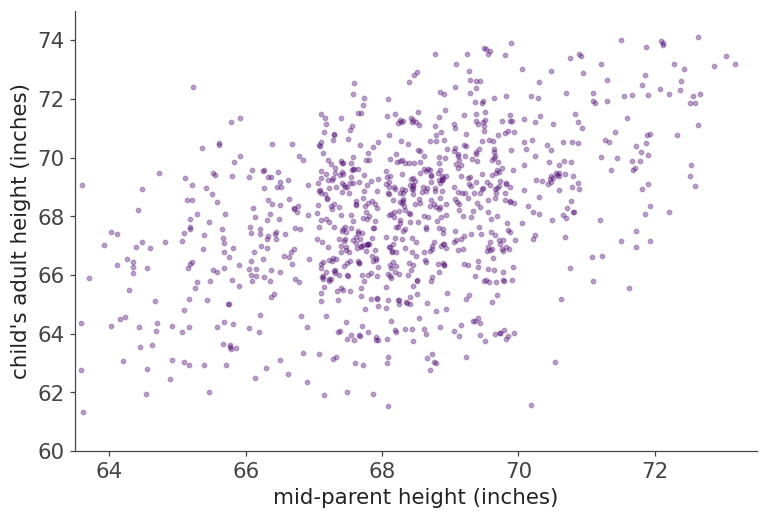

In [5]:
# @title

g = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/galton.csv")
gx, gy = g.parent.values.astype(float), g.child.values.astype(float)
ga, gb = fit(gx, gy)
jit = np.random.default_rng(1886)
gxj = gx + jit.uniform(-0.45, 0.45, len(gx)); gyj = gy + jit.uniform(-0.45, 0.45, len(gy))
GX = np.linspace(63.5, 73.5, 50)
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.scatter(gxj, gyj, color=PURPLE, s=8, alpha=0.35)
ax.set_xlabel("mid-parent height (inches)"); ax.set_ylabel("child's adult height (inches)")
ax.set_xlim(63.5, 73.5); ax.set_ylim(60, 75)
plt.show()  # f16_galton_scatter.png

## Regression toward the mean

If children were exactly as tall as their parents, the averages would follow the dashed line with slope 1. They follow a line with slope about 0.65. Children of very tall parents are tall, but on average less tall than their parents, and children of very short parents are short, but closer to average. Galton called this "regression towards mediocrity" (1886), and the word regression stayed with the method of fitting lines.

It happens because height is part family and part individual luck. Parents who are extremely tall are usually extremely tall partly by luck, and luck is not inherited.

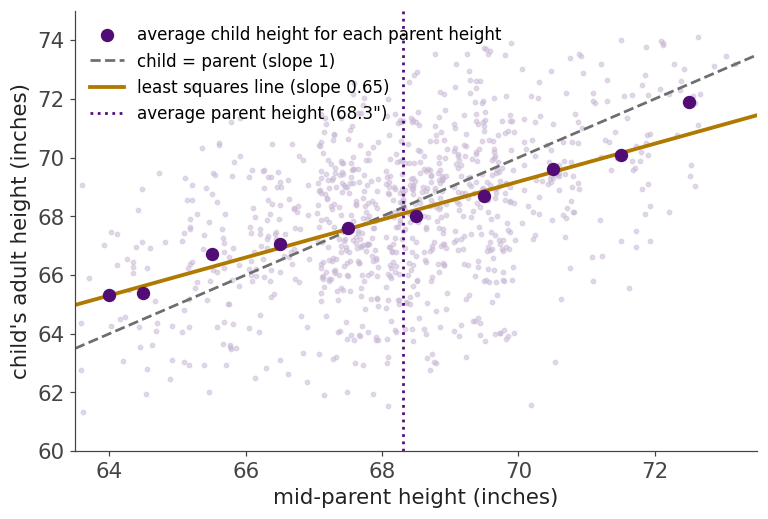

In [7]:
# @title
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.scatter(gxj, gyj, color=LIGHT, s=8, alpha=0.5)
grp = g.groupby("parent").child.agg(["mean", "size"]).reset_index()
grp = grp[grp["size"] >= 5]
ax.scatter(grp.parent, grp["mean"], color=PURPLE, s=60, zorder=3, label="average child height for each parent height")
ax.plot(GX, GX, color=GRAY, lw=1.8, ls="--", label="child = parent (slope 1)")
ax.plot(GX, ga + gb * GX, color=GOLD, lw=2.5, label=f"least squares line (slope {gb:.2f})")
ax.axvline(gx.mean(), color=PURPLE, ls=":", lw=1.8, label=f"average parent height ({gx.mean():.1f}\")")
ax.set_xlabel("mid-parent height (inches)"); ax.set_ylabel("child's adult height (inches)")
ax.set_xlim(63.5, 73.5); ax.set_ylim(60, 75); ax.legend(frameon=False, loc="upper left", fontsize=11)
plt.show()  # f17_galton_lines.png

## Regression to the mean in business

Synthetic data: 400 stores, each with a fixed quality plus a random shock each quarter. Nothing changes between quarters, yet this quarter's top 10% fall back and the bottom 10% improve. A manager who sent a consultant to the bottom stores would see improvement and credit the consultant.

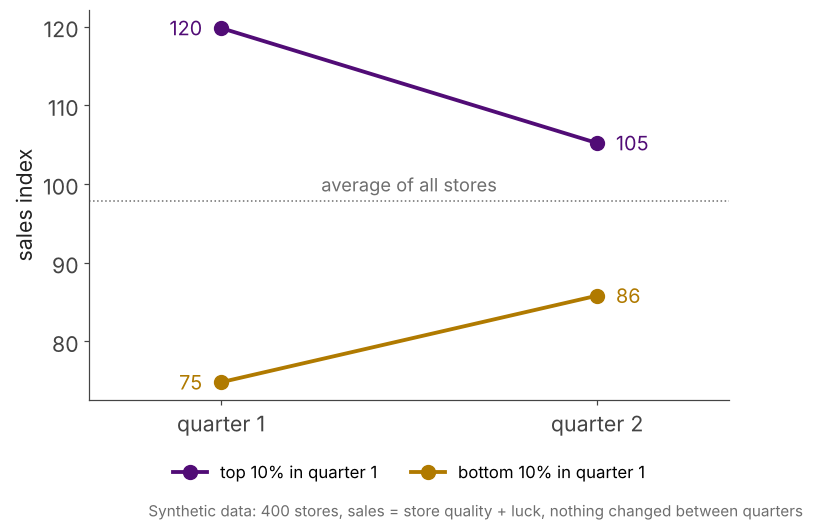

In [ ]:
# @title
# regression to the mean, synthetic: skill + luck, two periods
r2 = np.random.default_rng(7)
skill = r2.normal(100, 10, 400)
p1 = skill + r2.normal(0, 10, 400); p2 = skill + r2.normal(0, 10, 400)
top = p1 >= np.quantile(p1, 0.9); bot = p1 <= np.quantile(p1, 0.1)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for sel, col, lab in [(top, PURPLE, "top 10% in quarter 1"), (bot, GOLD, "bottom 10% in quarter 1")]:
    m1, m2 = p1[sel].mean(), p2[sel].mean()
    ax.plot([0, 1], [m1, m2], color=col, lw=2.5, marker="o", ms=9, label=lab)
    ax.text(-0.05, m1, f"{m1:.0f}", ha="right", va="center", color=col, fontsize=13)
    ax.text(1.05, m2, f"{m2:.0f}", ha="left", va="center", color=col, fontsize=13)
ax.axhline(p1.mean(), color=GRAY, ls=":", lw=1); ax.text(0.5, p1.mean() + 1.2, "average of all stores", ha="center", color=GRAY, fontsize=12)
ax.set_xticks([0, 1]); ax.set_xticklabels(["quarter 1", "quarter 2"]); ax.set_xlim(-0.35, 1.35)
ax.set_ylabel("sales index"); ax.legend(frameon=False, loc="upper center", fontsize=11, bbox_to_anchor=(0.5, -0.12), ncol=2)
fig.text(0.99, -0.12, "Synthetic data: 400 stores, sales = store quality + luck, nothing changed between quarters", ha="right", fontsize=10, color=GRAY)
plt.show()  # f18_regression_to_mean.png

## A wrong conclusion that feels right

Daniel Kahneman (*Thinking, Fast and Slow*, chapter 17) tells of flight instructors who noticed that cadets praised for an excellent landing usually did worse the next time, and cadets criticized for a poor one usually did better. They concluded that praise hurts and criticism helps. Regression to the mean explains the pattern with no effect of praise or criticism at all.

**Select on an extreme, measure again, and you will see a change even when nothing caused it.** As we saw when we discussed experimental design, finding out whether the feedback works would take a comparison group.

## A darker side of the history

Galton studied height as part of a larger project: he wanted to show that human qualities such as talent and character are inherited. He coined the term *eugenics* for the idea of improving the population through selective breeding, and he left money to University College London for the first professorship in eugenics. Its first holder, Karl Pearson, developed much of the statistics we use today, including the correlation coefficient. In 2020, UCL removed Galton's and Pearson's names from its buildings, and in 2021 it formally apologized for its history in eugenics.

The methods themselves are neutral: a regression line does not care what it is used for. Choosing what to study, and why, is the analyst's responsibility.